# Study the influence of parameters on energy.

As explained in the [official documentation](https://mendevi.readthedocs.io/latest/build/api/mendevi.models.trend.TrendNormlisator.html), this protocol models the influence of parameter $X_k$ on output $Y$, independently of the other contextual inputs. So we have $\tilde{Y}=\tilde{\phi}(X_k)$ and $\hat{Y}=a \tilde{Y}+b$. The model trys to minimise the erreor betwwen $\hat{Y}$ and the gound truth $Y = \phi(X_i)$.

He makes the strong assumption that the context parameter acts independently on the output as an affine denormalization function.

In [1]:
import matplotlib.pyplot as plt

from mendevi.cst.plot import FIGSIZE
from mendevi.models.trend import TrendEncodeEnergy

## Model Training

In [2]:
# model declaration
interest_label = "pixels"  # "quality" for the crf impact, "spatial_dct" for the texture...

model = TrendEncodeEnergy(
    interest_labels=[interest_label],
    weights=f"trend_{interest_label}",  # optional, for checkpoint (in ~/.cache/mendevi)
    niter=1000,  # number of training iterations, default 10000
    learning_rate=1e-5,  # default learning rate to 1e-4 (Adam gradient decay)
)

Load model from /home/robin/.cache/mendevi/trend_pixels.pk.xz...
█ 509.88 ms


In [3]:
# model training
dataset = "scatter.db"  # the dataset name, automatically downloaded
val = 0.2  # keep 80% of data for training, 20% for validation

if not model.is_fit():
    model.fit(
        dataset,
        table="t_enc_encode",  # optional, help to find the good SQL request
        select=f"uniform(vid_hash) >= {val}",
    )

In [4]:
model.validate(dataset, table="t_enc_encode", select=f"uniform(vid_hash) < {val}")

Validate 'Effect of a parameter on the encoding energy'...
█ get SQL extractor
█ perform SQL query
█ Validate on cluster hostname=abacus26-1.rennes.grid5000.fr...
█ █ this cluster contains 4068 observations
█ █ 1.40 s
█ Validate on cluster hostname=dahu-12.grenoble.grid5000.fr...
█ █ this cluster contains 676 observations
█ █ 398.70 ms
█ Validate on cluster hostname=gemini-2.lyon.grid5000.fr...
█ █ this cluster contains 477 observations
█ █ 282.82 ms
█ Validate on cluster hostname=nova-12.lyon.grid5000.fr...
█ █ this cluster contains 476 observations
█ █ 205.99 ms
█ Validate on cluster hostname=paradoxe-32.rennes.grid5000.fr...
█ █ this cluster contains 618 observations
█ █ 272.89 ms
█ Validate on cluster hostname=suzanne...
█ █ this cluster contains 467 observations
█ █ 354.55 ms
█ Validate on cluster hostname=yeti-2.grenoble.grid5000.fr...
█ █ this cluster contains 433 observations
█ █ 342.68 ms
█ 17 min 59 s
MAPE of log_act_duration_per_frame: 112.69%
RMS  of log_act_duration_per_fr

## Visualisation

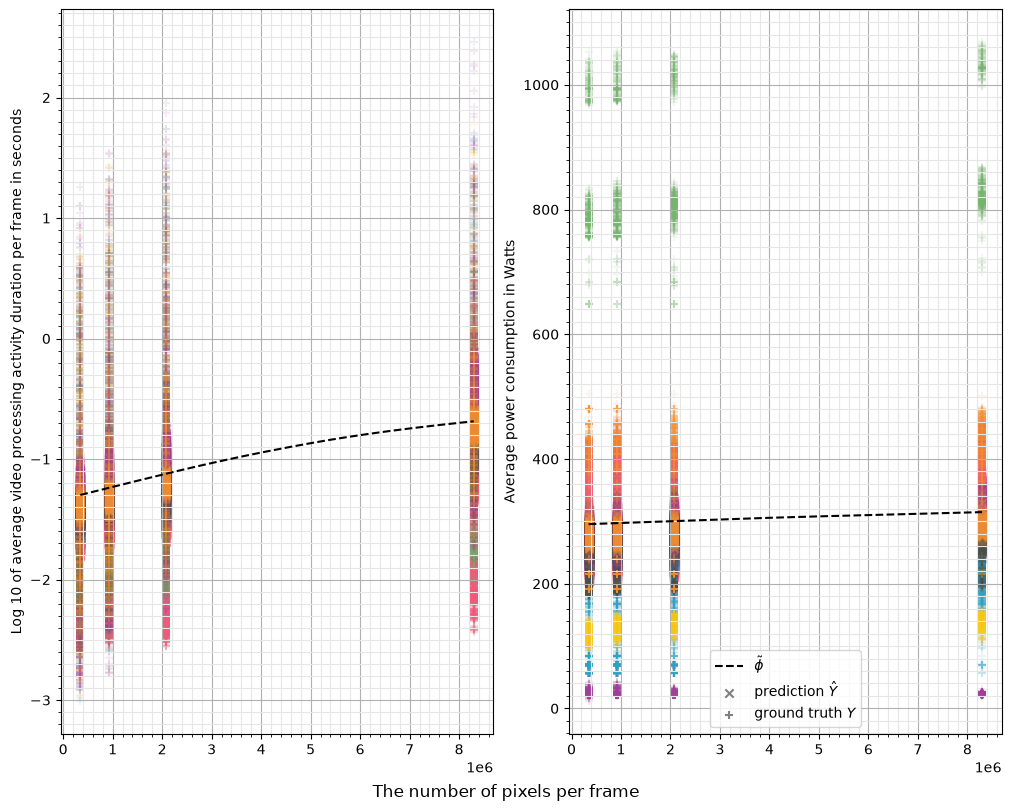

In [5]:
fig = plt.figure(layout="constrained", figsize=FIGSIZE)
model.fill_fig_phi(fig)
plt.legend()
plt.show()